# GCsp forecasts through intermediate parameters

The Euclid forecast-validation paper (Euclid Collaboration, *Euclid preparation VII*, Sect. 4.2.1)
does not differentiate the galaxy power spectrum directly with respect to the final cosmological
parameters. It goes through a halfway house instead: a handful of **shape** parameters plus a set of
**functions of redshift**, $H(z_i)$, $D_A(z_i)$, $f\sigma_8(z_i)$, $b\sigma_8(z_i)$ and the shot
noise $P_s(z_i)$, measured separately in every redshift bin. Only at the very end are these
constraints translated to cosmology with a Jacobian.

This notebook runs that two-stage recipe on top of CosmicJellyfish's validated JAX spectroscopic
observable, and checks that it lands on the same answer as the usual direct forecast. Along the way it
shows:

1. the intermediate observable reproduces the validated $P_{\rm obs}$ to machine precision,
2. paper-style finite differences and JAX autodiff give the same derivatives,
3. the structure of the intermediate Fisher matrix,
4. what $H(z)$, $D_A(z)$ and $f\sigma_8(z)$ are constrained to in each bin,
5. the projected cosmological constraints next to the direct ones.

The grid is deliberately coarse (24 $k$ × 12 $\mu$) so the whole notebook runs in about two minutes.

In [1]:
# Keep the output readable: CPU-only JAX and no third-party import chatter.
import os

os.environ.setdefault("JAX_PLATFORMS", "cpu")

import logging
import tempfile
import time
import warnings

warnings.filterwarnings("ignore", message="pkg_resources is deprecated")
warnings.filterwarnings("ignore", category=SyntaxWarning)
logging.getLogger("jax._src.xla_bridge").setLevel(logging.ERROR)

import jax

jax.config.update("jax_enable_x64", True)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import cosmicjellyfish.analysis.fishconsumer as fco
from cosmicjellyfish.LSSsurvey.gcsp_intermediate import GCspIntermediateForecast

FIGDIR = os.path.join("..", "docs", "source", "_static", "gcsp_intermediate")
os.makedirs(FIGDIR, exist_ok=True)
RESULTS = tempfile.mkdtemp(prefix="gcsp_intermediate_")
pd.set_option("display.float_format", "{:.5g}".format)

## 1. Set up the forecast

`GCspIntermediateForecast` builds the usual `FisherMatrix` configuration for Euclid GCsp (four
redshift bins between $z=0.9$ and $1.8$), the validated JAX observable, and the intermediate
observable on top of it. Fisher files from the direct comparison go to a temporary directory.

In [2]:
t0 = time.perf_counter()
forecast = GCspIntermediateForecast(
    options={
        "code": "jaxcosmo",
        "nonlinear": True,
        "feedback": 0,
        "spectro_Pk_k_samples": 24,
        "spectro_Pk_mu_samples": 12,
        "results_dir": RESULTS,
        "outroot": "gcsp_intermediate_notebook",
    },
    specifications={"kmin_GCsp": 0.01, "kmax_GCsp": 0.20, "spec_sigma_dz": 0.001},
    cosmoModel="LCDM",
)
inter = forecast.intermediate
print(f"Built in {time.perf_counter() - t0:.1f} s")
print("Redshift bins:", np.round(inter.z, 2))
print("Final parameters:", forecast.final_names)

Built in 15.7 s
Redshift bins: [1.   1.2  1.4  1.65]
Final parameters: ('10^9As', 'Omegam', 'Omegab', 'h', 'ns')


## 2. Intermediate parameters and the observable

The shape parameters are the paper's physical densities $\omega_b = \Omega_b h^2$,
$\omega_m = \Omega_m h^2$, together with $h$ and $n_s$. They only change the *shape* of the
de-wiggled spectrum $P_{\rm dw}/\sigma_8^2$; the amplitude lives entirely in
$f\sigma_8$ and $b\sigma_8$:

$$
P_{\rm obs}(k,\mu;z_i) = \frac{1}{q_\perp^2 q_\parallel}
\left[b\sigma_8(z_i) + f\sigma_8(z_i)\,\mu^2\right]^2
\frac{P_{\rm dw}(k,\mu;z_i)}{\sigma_8^2(z_i)}\,F_{\rm FoG}\,F_z + P_s(z_i),
$$

with $q_\parallel = H^{\rm fid}(z_i)/H(z_i)$ and $q_\perp = D_A(z_i)/D_A^{\rm fid}(z_i)$ setting
the Alcock-Paczynski distortion. Since $(b + f\mu^2)^2 P_{\rm dw}$ and
$(b\sigma_8 + f\sigma_8\mu^2)^2 P_{\rm dw}/\sigma_8^2$ are the same thing, the intermediate
observable must match the validated one exactly at the fiducial point.

In [7]:
fid = inter.fiducial_params()
shape = pd.Series({k: fid[k] for k in ("omegab", "h", "omegam", "ns")}, name="fiducial")
per_bin = pd.DataFrame(
    {
        "z": inter.z,
        "H [km/s/Mpc]": np.exp(inter.lnH_fid) * 299792.458,
        "D_A [Mpc]": np.exp(inter.lnDA_fid),
        "f sigma8": inter.fs8_fid,
        "b sigma8": inter.bs8_fid,
        "P_s": inter.ps_fid,
    },
    index=[f"bin {i + 1}" for i in range(inter.nbins)],
)
display(shape.to_frame())
display(per_bin.round(4))

base_lnp = forecast.base.lnp(forecast.base.fiducial)
inter_lnp = inter.lnp()
parity = max(np.max(np.abs(base_lnp[i] - inter_lnp[i])) for i in range(inter.nbins))
print(f"max |ln P_validated - ln P_intermediate| = {parity:.2e}")

,fiducial
omegab,2.244500000E-02
h,6.700000000E-01
omegam,1.436480000E-01
ns,9.600000000E-01


,z,H [km/s/Mpc],D_A [Mpc],f sigma8,b sigma8,P_s
bin 1,1.000000000E+00,1.206000000E+02,1.706046800E+03,4.387000000E-01,7.294000000E-01,0.000000000E+00
bin 2,1.200000000E+00,1.354554000E+02,1.764112800E+03,4.149000000E-01,7.362000000E-01,0.000000000E+00
bin 3,1.400000000E+00,1.513619000E+02,1.791647800E+03,3.915000000E-01,7.393000000E-01,0.000000000E+00
bin 4,1.650000000E+00,1.725829000E+02,1.797524900E+03,3.638000000E-01,7.328000000E-01,0.000000000E+00


max |ln P_validated - ln P_intermediate| = 1.78e-15


## 3. Finite differences versus autodiff

The finite-difference recipe follows the paper: central three-point differences with a relative
step for the shape parameters and the growth amplitudes, the five-point rule for $\ln H$ and
$\ln D_A$, and the exact $\partial \ln P_{\rm obs}/\partial P_s = 1/P_{\rm obs}$ for shot noise.
JAX differentiates the very same function.

One practical note: the no-wiggle spectrum is built with a Savitzky-Golay filter and then linearly
interpolated in $k$. Steps of order $10^{-3}$ straddle interpolation nodes and bias the
derivatives at the per-mille level, so the default step here is $5\times10^{-6}$.

In [8]:
t0 = time.perf_counter()
d_ad = inter.jacobian_ad()
t_ad = time.perf_counter() - t0
t0 = time.perf_counter()
d_fd = inter.jacobian_fd()
t_fd = time.perf_counter() - t0
print(f"autodiff {t_ad:.1f} s (includes compilation), finite differences {t_fd:.1f} s")

rel = {
    name: np.max(np.abs(d_ad[name] - d_fd[name])) / max(np.max(np.abs(d_ad[name])), 1e-30)
    for name in inter.parameter_names
}
pd.Series(rel, name="max relative difference").to_frame().T.style.format("{:.1e}")

autodiff 15.4 s (includes compilation), finite differences 0.1 s


,omegab,h,omegam,ns,lnDA_1,lnH_1,lnfs8_1,lnbs8_1,Ps_1,lnDA_2,lnH_2,lnfs8_2,lnbs8_2,Ps_2,lnDA_3,lnH_3,lnfs8_3,lnbs8_3,Ps_3,lnDA_4,lnH_4,lnfs8_4,lnbs8_4,Ps_4
max relative difference,1.4e-09,6.4e-10,2.0e-10,1.8e-10,1.3e-10,1.9e-10,2.1e-10,8.8e-11,8.4e-16,1.4e-10,1.9e-10,2.9e-10,8.6e-11,1.1e-15,1.5e-10,1.9e-10,2.7e-10,9.3e-11,1.0e-15,1.4e-10,2.1e-10,2.3e-10,8.0e-11,1.1e-15


## 4. The intermediate Fisher matrix

In each bin the Fisher matrix is the usual GCsp integral,

$$
F_{\alpha\beta}^{(i)} = \frac{V_i}{8\pi^2}\int_{-1}^{1}\!{\rm d}\mu\int_{k_{\rm min}}^{k_{\rm max}}
\!k^2\,{\rm d}k\;\frac{\partial \ln P_{\rm obs}}{\partial\theta_\alpha}
\frac{\partial \ln P_{\rm obs}}{\partial\theta_\beta}\left[\frac{n_i P_{\rm obs}}{1+n_i P_{\rm obs}}\right]^2,
$$

but the parameters split into a global block $\boldsymbol\theta_s = (\omega_b, h, \omega_m, n_s)$
and a local block per bin,
$\boldsymbol\theta_i = (\ln D_{A,i}, \ln H_i, \ln f\sigma_{8,i}, \ln b\sigma_{8,i}, P_{s,i})$.
A local parameter only changes the spectrum in its own bin, so different bins never talk to each
other directly. The full matrix has the block-arrowhead form of the paper (Eqs. 96-98):

$$
\mathbf F =
\begin{pmatrix}
\sum_i \mathbf F^{(i)}_{ss} & \mathbf F^{(1)}_{s1} & \mathbf F^{(2)}_{s2} & \cdots & \mathbf F^{(N)}_{sN}\\
\mathbf F^{(1)}_{1s} & \mathbf F^{(1)}_{11} & 0 & \cdots & 0\\
\mathbf F^{(2)}_{2s} & 0 & \mathbf F^{(2)}_{22} & \cdots & 0\\
\vdots & \vdots & & \ddots & \vdots\\
\mathbf F^{(N)}_{Ns} & 0 & 0 & \cdots & \mathbf F^{(N)}_{NN}
\end{pmatrix},
$$

where $\mathbf F_{ss}$ is $4\times4$, each $\mathbf F_{ii}$ is $5\times5$ and each
$\mathbf F_{si}$ is $4\times5$. The correlation plot below makes the pattern visible.

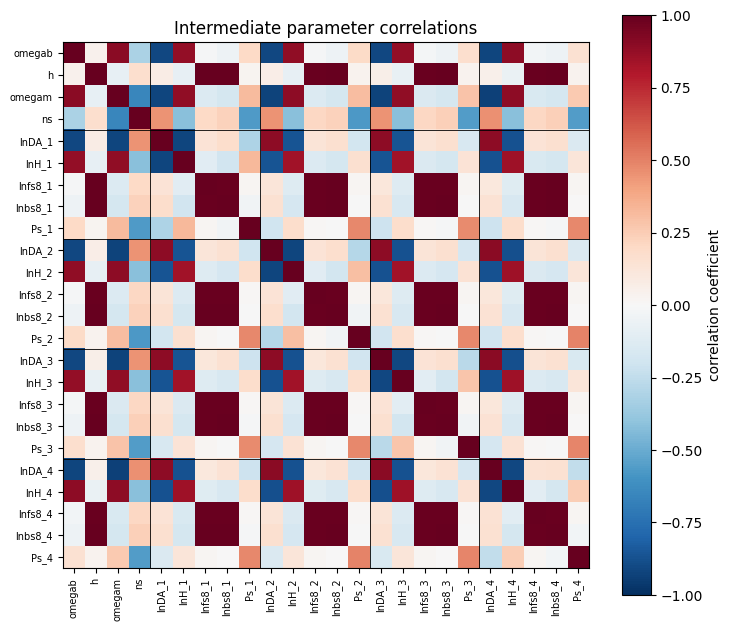

largest Fisher entry between bin 1 and bin 2 locals: 0.0e+00


In [9]:
F_int = forecast.fisher_intermediate(method="ad")
names = inter.parameter_names
cov = np.linalg.pinv(F_int)
sig = np.sqrt(np.diag(cov))
corr = cov / np.outer(sig, sig)

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(names)), names, rotation=90, fontsize=7)
ax.set_yticks(range(len(names)), names, fontsize=7)
for edge in 4 + 5 * np.arange(inter.nbins + 1) - 0.5:
    ax.axhline(edge, color="k", lw=0.6)
    ax.axvline(edge, color="k", lw=0.6)
fig.colorbar(im, ax=ax, label="correlation coefficient")
ax.set_title("Intermediate parameter correlations")
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, "correlation_matrix.png"), dpi=150)
plt.show()

nonzero = np.abs(F_int[np.ix_(range(4, 9), range(9, 14))]).max()
print(f"largest Fisher entry between bin 1 and bin 2 locals: {nonzero:.1e}")

## 5. What the survey measures in each bin

Galaxy bias and shot noise are nuisances, so we marginalise over $\ln b\sigma_{8,i}$ and $P_{s,i}$
(a Schur complement of the Fisher matrix). What is left constrains the shape parameters and three
functions per bin. The errors below are fully marginalised, including over the shape parameters.

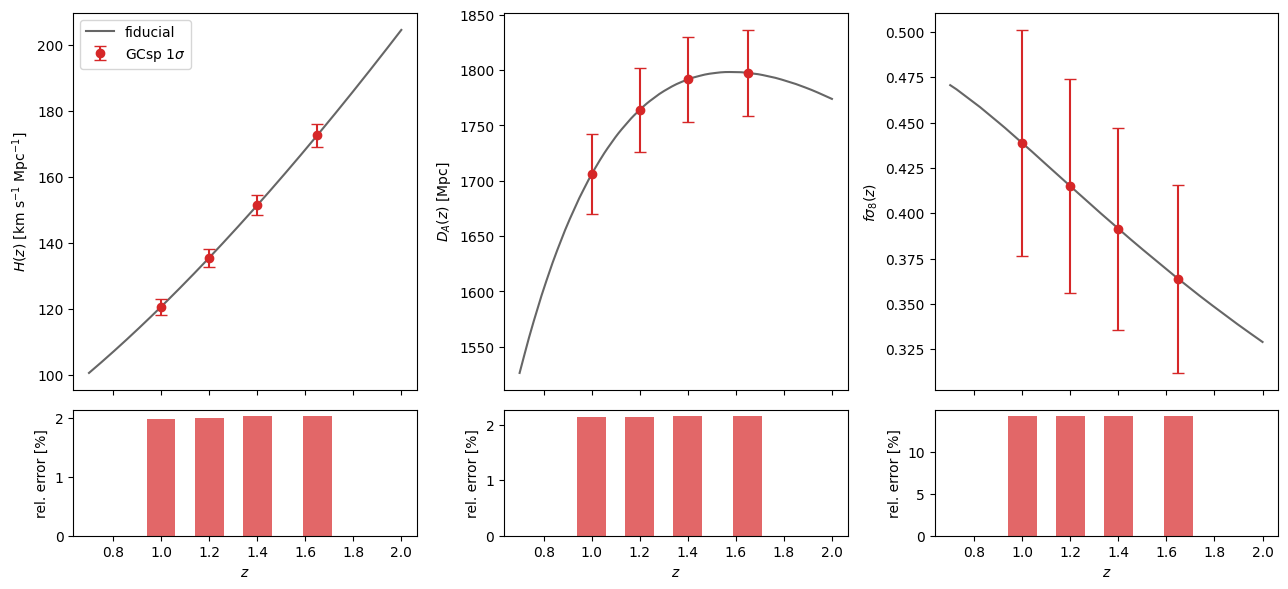

,sigma(H)/H [%],sigma(DA)/DA [%],sigma(fs8)/fs8 [%]
z = 1.00,1.990000000E+00,2.140000000E+00,1.422000000E+01
z = 1.20,2.000000000E+00,2.140000000E+00,1.422000000E+01
z = 1.40,2.030000000E+00,2.160000000E+00,1.424000000E+01
z = 1.65,2.040000000E+00,2.160000000E+00,1.424000000E+01


In [10]:
reduced, kept = forecast.reduced_fisher(fisher=F_int)
binned = forecast.binned_constraints(reduced, kept)

params = {n: forecast.intermediate._base_cosmo[n] for n in forecast.base.cosmo_names}
zz = np.linspace(0.7, 2.0, 200)
tab = forecast.base.theory.tables(params, zz, forecast.base.k_hmpc[:2], False)
curves = {
    "H": np.asarray(tab.h_over_c) * 299792.458,
    "DA": np.asarray(tab.chi) / (1 + zz),
    "fs8": np.asarray(tab.growth_rate) * np.asarray(tab.sigma8),
}
labels = {
    "H": r"$H(z)$ [km s$^{-1}$ Mpc$^{-1}$]",
    "DA": r"$D_A(z)$ [Mpc]",
    "fs8": r"$f\sigma_8(z)$",
}

fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
for col, key in enumerate(("H", "DA", "fs8")):
    b = binned[key]
    axes[0, col].plot(zz, curves[key], color="0.4", lw=1.5, label="fiducial")
    axes[0, col].errorbar(b["z"], b["fiducial"], yerr=b["sigma"], fmt="o", color="C3",
                          capsize=4, label=r"GCsp $1\sigma$")
    axes[0, col].set_ylabel(labels[key])
    axes[1, col].bar(b["z"], 100 * b["sigma"] / b["fiducial"], width=0.12, color="C3", alpha=0.7)
    axes[1, col].set_ylabel("rel. error [%]")
    axes[1, col].set_xlabel("$z$")
axes[0, 0].legend()
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, "binned_constraints.png"), dpi=150)
plt.show()

pd.DataFrame(
    {f"sigma({k})/{k} [%]": 100 * binned[k]["sigma"] / binned[k]["fiducial"] for k in binned},
    index=[f"z = {z:.2f}" for z in inter.z],
).round(2)

## 6. Projecting onto cosmology

Every kept intermediate parameter is a function of the final ones,
$\tilde\theta_a = \tilde\theta_a(\Omega_m, \Omega_b, h, n_s, A_s)$, so the Fisher matrix
transforms with the chain rule

$$
\mathbf F_{\rm final} = \mathbf J^{T}\,\tilde{\mathbf F}\,\mathbf J,
\qquad J_{a\beta} = \frac{\partial\tilde\theta_a}{\partial\theta^{\rm final}_\beta}.
$$

This is done by the general helper `fisher_operations.reparametrise`, with $\mathbf J$ from JAX.
Note the direction: $\mathbf J$ differentiates the *old* parameters with respect to the *new*
ones. That is different from `fisher_derived`, which propagates the *covariance* to derived
quantities, $\mathbf C' = \mathbf A^{T}\mathbf C\,\mathbf A$ with
$\mathbf A = \partial(\text{derived})/\partial(\text{old})$.

The Jacobian is sparse and easy to read: the amplitude only enters through $f\sigma_8$, and
$\omega_b$, $\omega_m$ pick up an $h$ dependence from $\omega = \Omega h^2$.

In [11]:
result = forecast.run(method="ad")
J = pd.DataFrame(result["jacobian"], index=result["kept_names"], columns=result["final_names"])
display(J.head(7).round(4))

projected = forecast.projected_fisher_matrix(
    result["fisher_reduced"], result["kept_names"], result["jacobian"], result["final_names"]
)
t0 = time.perf_counter()
direct_ad = forecast.direct_fisher(method="ad")
print(f"direct autodiff Fisher in {time.perf_counter() - t0:.1f} s")

order = [list(direct_ad.param_names).index(n) for n in result["final_names"]]
F_direct = np.asarray(direct_ad.fisher_matrix)[np.ix_(order, order)]
s_int = np.sqrt(np.diag(np.linalg.inv(result["fisher_final"])))
s_dir = np.sqrt(np.diag(np.linalg.inv(F_direct)))
print("max relative Fisher difference:",
      f"{np.max(np.abs(result['fisher_final'] - F_direct) / np.abs(F_direct)):.1e}")
pd.DataFrame({"intermediate": s_int, "direct": s_dir, "ratio": s_int / s_dir},
             index=result["final_names"])

,10^9As,Omegam,Omegab,h,ns
omegab,0.000000000E+00,0.000000000E+00,4.489000000E-01,6.700000000E-02,0.000000000E+00
h,0.000000000E+00,0.000000000E+00,0.000000000E+00,1.000000000E+00,0.000000000E+00
omegam,0.000000000E+00,4.489000000E-01,0.000000000E+00,4.288000000E-01,0.000000000E+00
ns,0.000000000E+00,0.000000000E+00,0.000000000E+00,0.000000000E+00,1.000000000E+00
lnDA_1,0.000000000E+00,-5.735000000E-01,0.000000000E+00,-1.492500000E+00,0.000000000E+00
lnH_1,0.000000000E+00,1.080200000E+00,0.000000000E+00,1.492500000E+00,0.000000000E+00
lnfs8_1,2.381000000E-01,2.290300000E+00,-5.910900000E+00,1.656900000E+00,3.730000000E-01


Computing derivatives of Galaxy Clustering Spectro
>> Computing Derivs >>


direct autodiff Fisher in 23.1 s
max relative Fisher difference: 9.7e-13


,intermediate,direct,ratio
10^9As,3.050506086E-02,3.050506086E-02,1.000000000E+00
Omegam,5.190349957E-03,5.190349957E-03,1.000000000E+00
Omegab,1.476319804E-03,1.476319804E-03,1.000000000E+00
h,1.313730119E-02,1.313730119E-02,1.000000000E+00
ns,1.141446352E-02,1.141446352E-02,1.000000000E+00


Plot saved to: ../docs/source/_static/gcsp_intermediate/triangle_direct_vs_intermediate.png


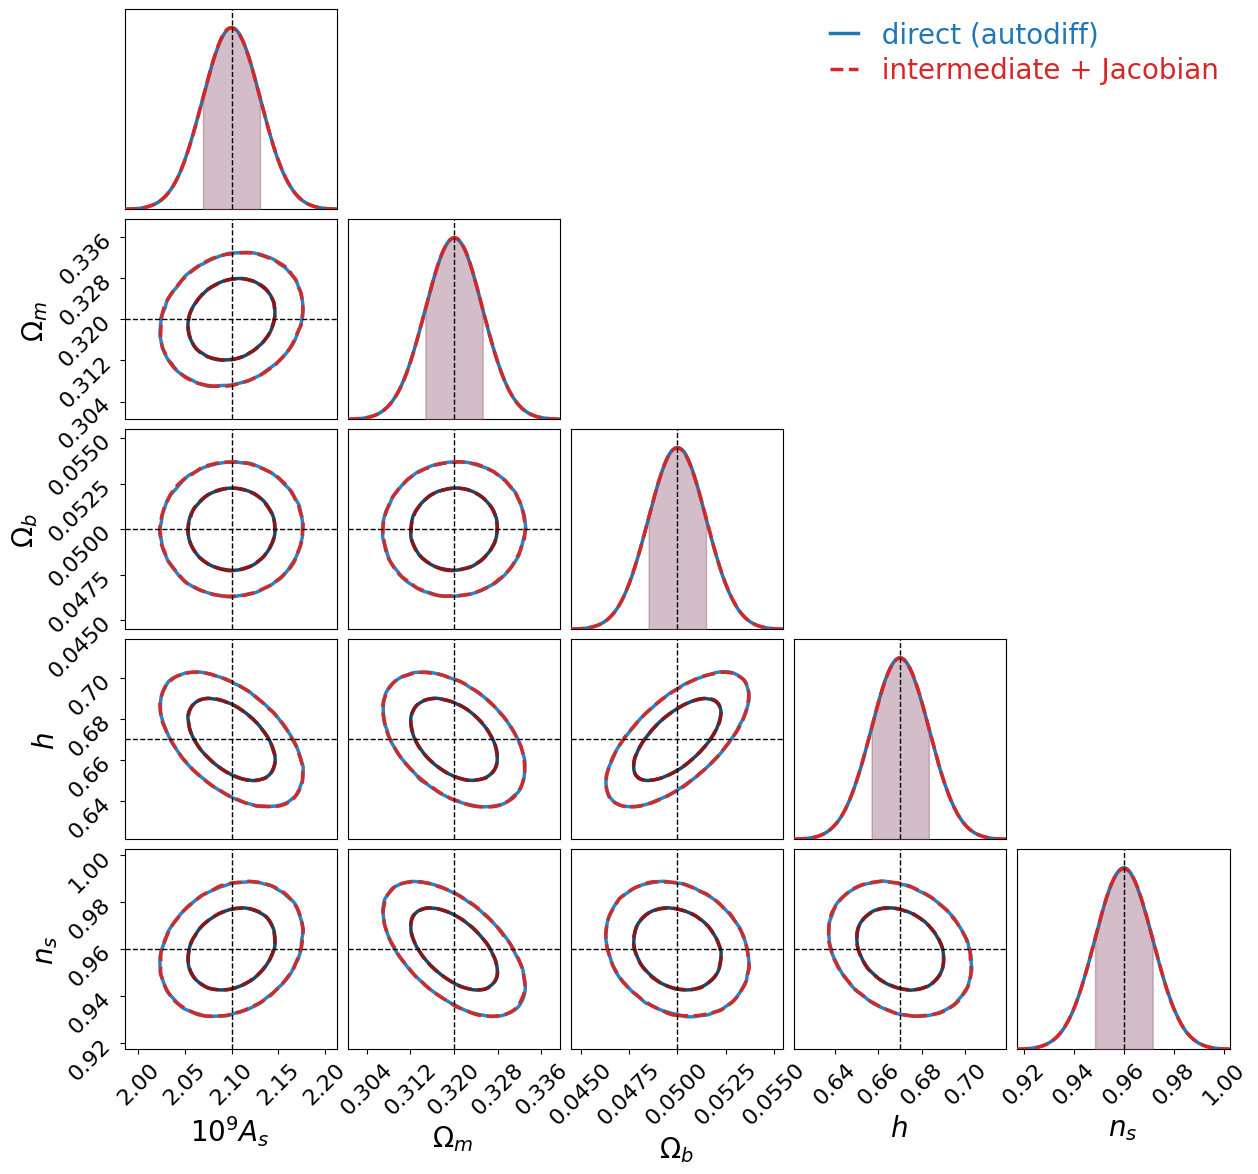

In [12]:
param_labels = {
    "10^9As": r"$10^9 A_s$",
    "Omegam": r"$\Omega_m$",
    "Omegab": r"$\Omega_b$",
    "h": r"$h$",
    "ns": r"$n_s$",
}
fig = fco.make_triangle_plot(
    fishers=[direct_ad, projected],
    fisher_labels=["direct (autodiff)", "intermediate + Jacobian"],
    params=list(result["final_names"]),
    colors=["#1f77b4", "#d62728"],
    ls_fisher=["-", "--"],
    truth_values=direct_ad.get_param_names_fiducial_dict(),
    param_labels=param_labels,
    savefile=os.path.join(FIGDIR, "triangle_direct_vs_intermediate.png"),
)

## 7. Finite differences end to end

Finally the all-finite-difference version: paper-style intermediate derivatives with a
finite-difference Jacobian, against the direct forecast with its standard 1% steps. The
intermediate route agrees with autodiff to many digits; the sub-percent offsets come from the
direct forecast's step size, and shrink to zero as that step is reduced.

Computing derivatives of Galaxy Clustering Spectro
>> Computing Derivs >>




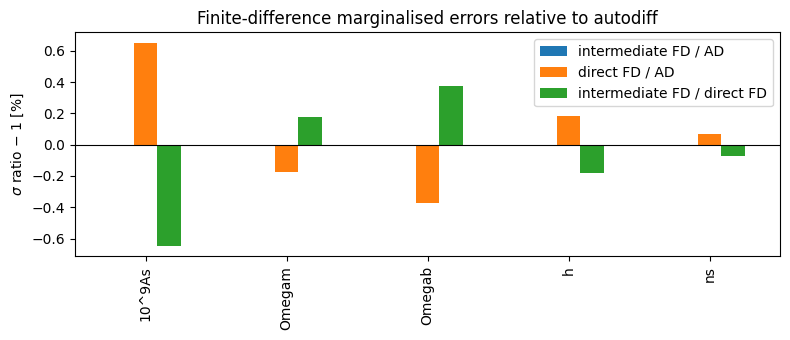

,intermediate FD / AD,direct FD / AD,intermediate FD / direct FD
10^9As,1.000000000E+00,1.006530000E+00,9.935100000E-01
Omegam,1.000000000E+00,9.982300000E-01,1.001770000E+00
Omegab,1.000000000E+00,9.962900000E-01,1.003730000E+00
h,1.000000000E+00,1.001840000E+00,9.981600000E-01
ns,1.000000000E+00,1.000710000E+00,9.992900000E-01


In [13]:
fd_result = forecast.run(method="fd", jacobian_method="fd")
direct_fd = forecast.direct_fisher(method="fd")
order = [list(direct_fd.param_names).index(n) for n in fd_result["final_names"]]
F_direct_fd = np.asarray(direct_fd.fisher_matrix)[np.ix_(order, order)]
s_int_fd = np.sqrt(np.diag(np.linalg.inv(fd_result["fisher_final"])))
s_dir_fd = np.sqrt(np.diag(np.linalg.inv(F_direct_fd)))

table = pd.DataFrame(
    {
        "intermediate FD / AD": s_int_fd / s_int,
        "direct FD / AD": s_dir_fd / s_dir,
        "intermediate FD / direct FD": s_int_fd / s_dir_fd,
    },
    index=fd_result["final_names"],
)
ax = (table - 1.0).mul(100).plot.bar(figsize=(8, 3.5))
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel(r"$\sigma$ ratio $-$ 1 [%]")
ax.set_title("Finite-difference marginalised errors relative to autodiff")
plt.tight_layout()
plt.savefig(os.path.join(FIGDIR, "fd_vs_ad_ratios.png"), dpi=150)
plt.show()
table.round(5)

## Takeaways

- Written in $f\sigma_8$/$b\sigma_8$ form, the observable is identical to the validated one, so the
  two-stage forecast is a pure change of variables and reproduces the direct Fisher matrix.
- Paper-style finite differences and JAX autodiff agree to about $10^{-10}$ once the step is small
  compared with the no-wiggle interpolation spacing.
- The per-bin constraints on $H$, $D_A$ and $f\sigma_8$ are the model-independent part of the
  measurement; any cosmology can be plugged in afterwards with `fisher_operations.reparametrise`.